# 🧬 CRISPR DeepHF — Notebook 2: Tier-1 Baselines (Gradient-Boosted Trees)

**MLSN F26 · Group 2 · Tier 1**

This notebook consumes the cleaned dataset from **Notebook 1** and trains the
project's Tier-1 baselines — the same family of models the DeepHF paper used as
its classical reference — across all three Cas9 variants.

### Roadmap
1. Load the cleaned, split-labelled data (`data/processed/deephf_clean_all.csv`).
2. Engineer **439 biological sequence features** from each 21-mer.
3. Rebuild the exact train/val/test partitions from the frozen split labels.
4. Train & benchmark: **Ridge**, **LightGBM**, **XGBoost**, **CatBoost**, and a
   **blended ensemble** — on WT-SpCas9, eSpCas9(1.1), and SpCas9-HF1.
5. Publication-quality figures, model serialisation, and a test-prediction
   export for benchmarking against Tier 2 (CNN/BiLSTM) and Tier 3 (multi-task).

> **Metrics:** Pearson *r* and Spearman *ρ* (the paper's headline metrics), plus
> RMSE, MAE and R².

> **Note on optional libraries:** LightGBM/XGBoost/CatBoost are imported
> *optionally*. If a library is not installed in your environment, that model is
> skipped automatically and the rest of the notebook still runs.

In [1]:
# =============================================================================
# ENVIRONMENT SETUP  --  run ONE of the two blocks below
# =============================================================================

# -----------------------------------------------------------------------------
# [A] LOCAL (conda env: mlsn-group-2)  <-- active by default
# -----------------------------------------------------------------------------
import sys
from pathlib import Path

# Find the project root (the folder that contains `src/crispr_deephf`).
_here = Path.cwd()
ROOT = next(
    (p for p in (_here, *_here.parents) if (p / "src" / "crispr_deephf").is_dir()),
    _here,
)
sys.path.insert(0, str(ROOT / "src"))

# -----------------------------------------------------------------------------
# [B] GOOGLE COLAB  --  uncomment this whole block to run on Colab (GPU/faster)
# -----------------------------------------------------------------------------
# !pip install -q lightgbm xgboost catboost openpyxl pandas numpy scikit-learn matplotlib seaborn joblib
# from google.colab import drive
# drive.mount('/content/drive')
# # Point ROOT at the shared project folder on your Drive:
# from pathlib import Path
# import sys
# ROOT = Path('/content/drive/MyDrive/Google_Colab_Share_Folder/MLSN_F26_Group_2_(CRISPR)')
# sys.path.insert(0, str(ROOT / 'src'))
# # ---- OR, instead of Drive, clone the GitHub repo into Colab: ----
# # !git clone https://github.com/<your-org>/mlsn-group-2.git
# # ROOT = Path('/content/mlsn-group-2'); sys.path.insert(0, str(ROOT / 'src'))

# -----------------------------------------------------------------------------
from crispr_deephf import config, data, features, models, plots

paths = config.get_paths(ROOT)
plots.set_style()
print(f"crispr_deephf v{config.__dict__.get('__version__', '')}".strip())
print("Project root :", paths.root)
print("Processed dir:", paths.data_processed)

crispr_deephf v
Project root : C:\conda_projects\mlsn-group-2
Processed dir: C:\conda_projects\mlsn-group-2\data\processed


## 1. Load the cleaned data from Notebook 1

In [2]:
clean_path = paths.data_processed / config.CLEAN_ALL_CSV
if not clean_path.exists():
    raise FileNotFoundError(
        f"{clean_path} not found. Run 01_data_cleaning.ipynb first to generate it."
    )

df = data.load_clean(clean_path)
print("Loaded cleaned dataset:", df.shape)
df.head()

Loaded cleaned dataset: (59852, 10)


,gRNA_ID,gRNA_Seq,PAM,21mer,WT_Efficiency,eSpCas9_Efficiency,SpCas9_HF1_Efficiency,WT_split,eSp_split,HF1_split
0,GRNA-1,AAAAAAAAACTCCAAAACCC,TGG,AAAAAAAAACTCCAAAACCCT,0.168570,0.142063,0.093147,train,train,train
1,GRNA-2,AAAAAACAACAAGAAGCACA,AGG,AAAAAACAACAAGAAGCACAA,0.099624,0.051901,0.064951,train,train,val
2,GRNA-3,AAAAAACACAAGCAAGACCG,TGG,AAAAAACACAAGCAAGACCGT,0.247750,0.043573,0.061797,train,train,train
3,GRNA-4,AAAAAACAGATGCCACCTGT,GGG,AAAAAACAGATGCCACCTGTG,0.141232,0.052343,0.057246,train,train,train
4,GRNA-5,AAAAAACCCGTAGATAGCCT,CGG,AAAAAACCCGTAGATAGCCTC,0.045803,0.046234,0.067596,test,test,test


## 2. Engineer 439 biological sequence features
Gradient-boosted trees shine on tabular inputs, so we turn each 21-mer into 439
hand-crafted features: positional one-hot (84) + positional dinucleotides (320)
+ global counts/frequencies (24) + regional GC content (7) + biological motifs (4,
incl. the Pol III `TTTT` terminator). See `crispr_deephf.features` for details.

In [3]:
X_all, feature_names = features.extract_crispr_features(df["21mer"].tolist())
print("Feature matrix:", X_all.shape)

Extracted 439 features for 59,852 sequences in 1.31s (100.2 MB).
Feature matrix: (59852, 439)


## 3. Rebuild the train/val/test splits from the frozen labels
`get_split_arrays` reads the `*_split` columns written by Notebook 1, guaranteeing
the partitions match exactly (no re-derivation, no seed drift).

In [4]:
variant_splits = {t: data.get_split_arrays(df, X_all, t) for t in config.TARGET_COLS}

for t in config.TARGET_COLS:
    s = variant_splits[t]
    print(f"{config.TARGET_LABELS[t]:<14} | train {len(s['train']['y']):>6,} | "
          f"val {len(s['val']['y']):>5,} | test {len(s['test']['y']):>5,}")

WT-SpCas9      | train 42,536 | val 4,727 | test 8,341
eSpCas9(1.1)   | train 44,841 | val 4,983 | test 8,793
SpCas9-HF1     | train 43,518 | val 4,836 | test 8,534


## 4. Which models are available?
`available_trainers()` returns every model installed in the current environment.
Ridge (scikit-learn) is always present; the three boosters appear only if their
library imported successfully.

In [5]:
trainers = models.available_trainers()
print("Models to train:", list(trainers))
boosters = [m for m in trainers if m != "Ridge"]
if not boosters:
    print("\n⚠  No gradient-boosting libraries found.")
    print("   Install them (pip install lightgbm xgboost catboost) for the full",
          "Tier-1 benchmark; the notebook will run with Ridge only otherwise.")

Models to train: ['Ridge', 'LightGBM', 'XGBoost', 'CatBoost']


## 5. Train & benchmark across all three Cas9 variants
For each variant we train every available model with early stopping on the
validation set, then evaluate on the held-out test set. The **ensemble** is the
simple mean of the available boosters.

In [6]:
import time
import numpy as np
import pandas as pd

all_models, all_test_preds, metrics_rows = {}, {}, []

for target in config.TARGET_COLS:
    print("=" * 68)
    print(f" TRAINING TIER-1 BASELINES FOR: {config.TARGET_LABELS[target]}")
    print("=" * 68)
    s = variant_splits[target]
    Xtr, ytr = s["train"]["X"], s["train"]["y"]
    Xva, yva = s["val"]["X"], s["val"]["y"]
    Xte, yte = s["test"]["X"], s["test"]["y"]

    fitted, preds = {}, {}
    for name, trainer in trainers.items():
        t0 = time.time()
        model = trainer(Xtr, ytr, Xva, yva)
        dt = time.time() - t0
        p = model.predict(Xte)
        fitted[name], preds[name] = model, p
        row = models.compute_metrics(yte, p, name, "Test", target)
        row["Train_Time_s"] = round(dt, 2)
        metrics_rows.append(row)
        print(f"  {name:<9} | r {row['Pearson_r']:.4f} | rho {row['Spearman_rho']:.4f} | {dt:5.1f}s")

    # Blended ensemble = mean of available boosters.
    booster_preds = [preds[b] for b in boosters if b in preds]
    if len(booster_preds) >= 2:
        ens = np.mean(booster_preds, axis=0)
        preds["Ensemble"] = ens
        row = models.compute_metrics(yte, ens, "Ensemble", "Test", target)
        row["Train_Time_s"] = np.nan
        metrics_rows.append(row)
        print(f"  {'Ensemble':<9} | r {row['Pearson_r']:.4f} | rho {row['Spearman_rho']:.4f}")

    all_models[target], all_test_preds[target] = fitted, preds

metrics_df = pd.DataFrame(metrics_rows)
metrics_csv = paths.results / "tier1_baseline_metrics.csv"
metrics_df.to_csv(metrics_csv, index=False)
print(f"\nSaved metrics -> {metrics_csv}")

 TRAINING TIER-1 BASELINES FOR: WT-SpCas9
  Ridge     | r 0.7692 | rho 0.7807 |   0.2s


c:\Users\Ovalt\.conda\envs\mlsn-f26-group2\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 1.0812677686544703e-07.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
c:\Users\Ovalt\.conda\envs\mlsn-f26-group2\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


  LightGBM  | r 0.8634 | rho 0.8433 |   5.4s
  XGBoost   | r 0.8625 | rho 0.8455 |  11.2s
  CatBoost  | r 0.8537 | rho 0.8390 |   7.3s
  Ensemble  | r 0.8639 | rho 0.8468
 TRAINING TIER-1 BASELINES FOR: eSpCas9(1.1)
  Ridge     | r 0.7405 | rho 0.7507 |   0.1s


c:\Users\Ovalt\.conda\envs\mlsn-f26-group2\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 8.5767752011634e-08.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
c:\Users\Ovalt\.conda\envs\mlsn-f26-group2\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


  LightGBM  | r 0.8147 | rho 0.8212 |   4.1s
  XGBoost   | r 0.8164 | rho 0.8237 |   9.6s
  CatBoost  | r 0.8056 | rho 0.8142 |   6.4s
  Ensemble  | r 0.8167 | rho 0.8242
 TRAINING TIER-1 BASELINES FOR: SpCas9-HF1
  Ridge     | r 0.7568 | rho 0.7488 |   0.1s


c:\Users\Ovalt\.conda\envs\mlsn-f26-group2\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 9.778349152611554e-08.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
c:\Users\Ovalt\.conda\envs\mlsn-f26-group2\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


  LightGBM  | r 0.8338 | rho 0.8223 |   4.3s
  XGBoost   | r 0.8322 | rho 0.8223 |   9.5s
  CatBoost  | r 0.8212 | rho 0.8131 |   6.4s
  Ensemble  | r 0.8337 | rho 0.8238

Saved metrics -> C:\conda_projects\mlsn-group-2\results\tier1_baseline_metrics.csv


## 6. Master benchmark table

In [7]:
pivot = metrics_df.pivot_table(
    index="Model", columns="Target",
    values=["Pearson_r", "Spearman_rho", "RMSE", "R2"],
)
order = ["Ridge", "LightGBM", "XGBoost", "CatBoost", "Ensemble"]
pivot = pivot.reindex([m for m in order if m in pivot.index])
display(pivot.round(4))

display(metrics_df[["Target", "Model", "Pearson_r", "Spearman_rho",
                    "RMSE", "MAE", "R2", "Train_Time_s"]].round(4))

Pearson_r                                   \
Target   SpCas9_HF1_Efficiency WT_Efficiency eSpCas9_Efficiency   
Model                                                             
Ridge                   0.7568        0.7692             0.7405   
LightGBM                0.8338        0.8634             0.8147   
XGBoost                 0.8322        0.8625             0.8164   
CatBoost                0.8212        0.8537             0.8056   
Ensemble                0.8337        0.8639             0.8167   

                            R2                                   \
Target   SpCas9_HF1_Efficiency WT_Efficiency eSpCas9_Efficiency   
Model                                                             
Ridge                   0.5727        0.5916             0.5480   
LightGBM                0.6930        0.7439             0.6626   
XGBoost                 0.6901        0.7421             0.6653   
CatBoost                0.6695        0.7251             0.6459   
Ensemble                0.6910        0.7433             0.6646   

                          RMSE                                   \
Target   SpCas9_HF1_Efficiency WT_Efficiency eSpCas9_Efficiency   
Model                                                             
Ridge                   0.1360        0.1391             0.1253   
LightGBM                0.1153        0.1101             0.1083   
XGBoost                 0.1158        0.1105             0.1079   
CatBoost                0.1196        0.1141             0.1109   
Ensemble                0.1157        0.1102             0.1080   

                  Spearman_rho                                   
Target   SpCas9_HF1_Efficiency WT_Efficiency eSpCas9_Efficiency  
Model                                                            
Ridge                   0.7488        0.7807             0.7507  
LightGBM                0.8223        0.8433             0.8212  
XGBoost                 0.8223        0.8455             0.8237  
CatBoost                0.8131        0.8390             0.8142  
Ensemble                0.8238        0.8468             0.8242

,Target,Model,Pearson_r,Spearman_rho,RMSE,MAE,R2,Train_Time_s
0,WT_Efficiency,Ridge,0.7692,0.7807,0.1391,0.1044,0.5916,0.16
1,WT_Efficiency,LightGBM,0.8634,0.8433,0.1101,0.0795,0.7439,5.41
2,WT_Efficiency,XGBoost,0.8625,0.8455,0.1105,0.0800,0.7421,11.24
3,WT_Efficiency,CatBoost,0.8537,0.8390,0.1141,0.0833,0.7251,7.31
4,WT_Efficiency,Ensemble,0.8639,0.8468,0.1102,0.0799,0.7433,NaN
5,eSpCas9_Efficiency,Ridge,0.7405,0.7507,0.1253,0.0985,0.5480,0.13
6,eSpCas9_Efficiency,LightGBM,0.8147,0.8212,0.1083,0.0834,0.6626,4.09
7,eSpCas9_Efficiency,XGBoost,0.8164,0.8237,0.1079,0.0831,0.6653,9.57
8,eSpCas9_Efficiency,CatBoost,0.8056,0.8142,0.1109,0.0863,0.6459,6.44
9,eSpCas9_Efficiency,Ensemble,0.8167,0.8242,0.1080,0.0834,0.6646,NaN


## 7. Publication-quality visualisations
1. Model performance comparison (Pearson *r* & Spearman *ρ*).
2. Predicted-vs-actual hexbins for the best available model.
3. Top-25 sequence feature importances.
4. Residual distributions.

Showcase model: Ensemble


C:\Users\Ovalt\AppData\Local\Temp\ipykernel_10616\743671092.py:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
C:\Users\Ovalt\AppData\Local\Temp\ipykernel_10616\743671092.py:23: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
c:\conda_projects\mlsn-group-2\src\crispr_deephf\plots.py:114: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=imp, x="Importance", y="Feature", palette="viridis")
C:\Users\Ovalt\AppData\Local\Temp\ipykernel_10616\743671092.py:38: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
C:\Users\Ovalt\AppData\Local\Temp\ipykernel_10616\743671092.py:45: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


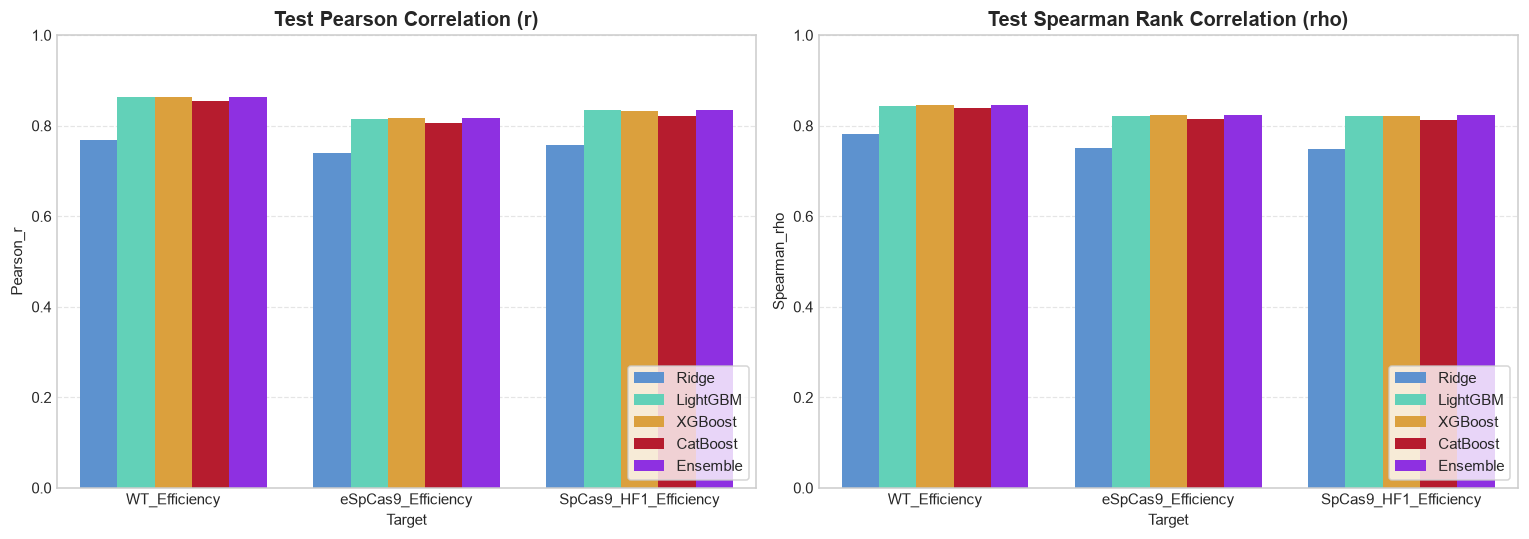

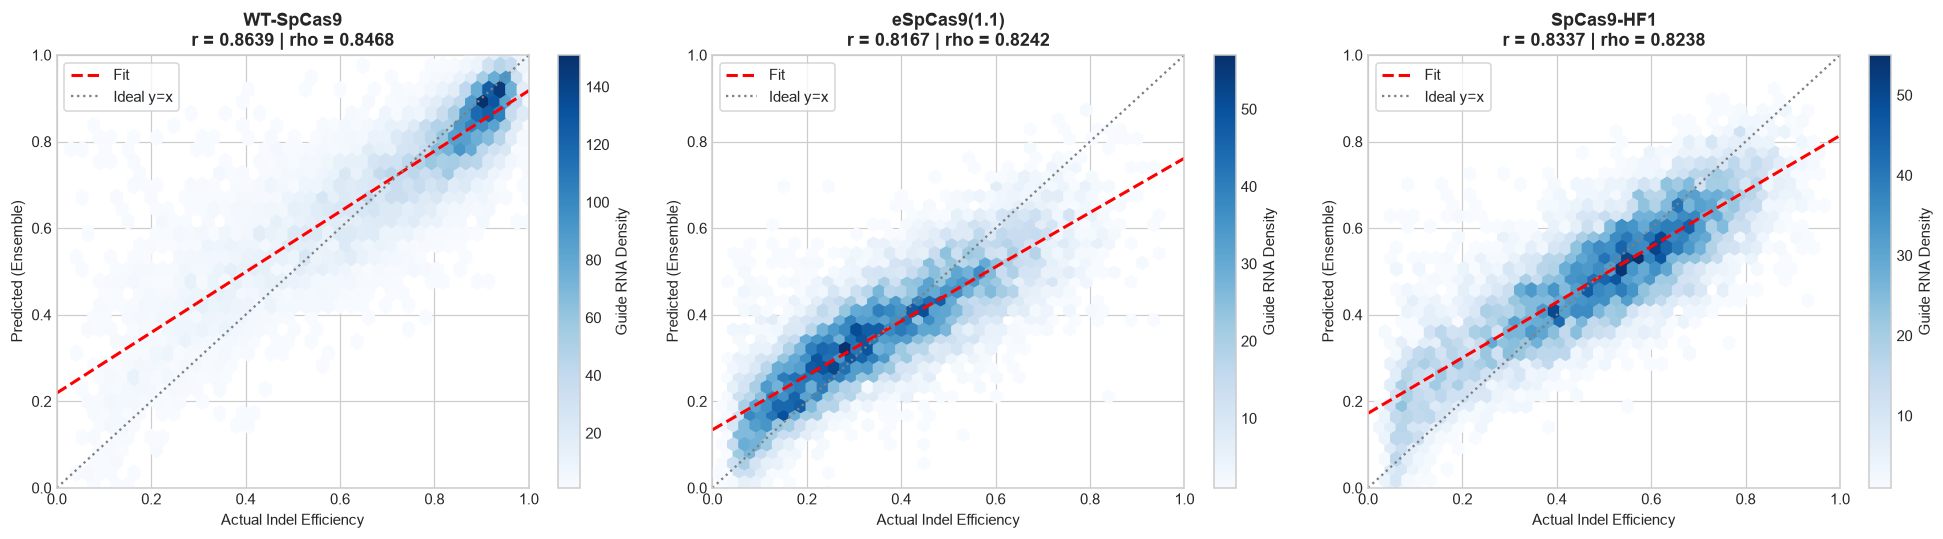

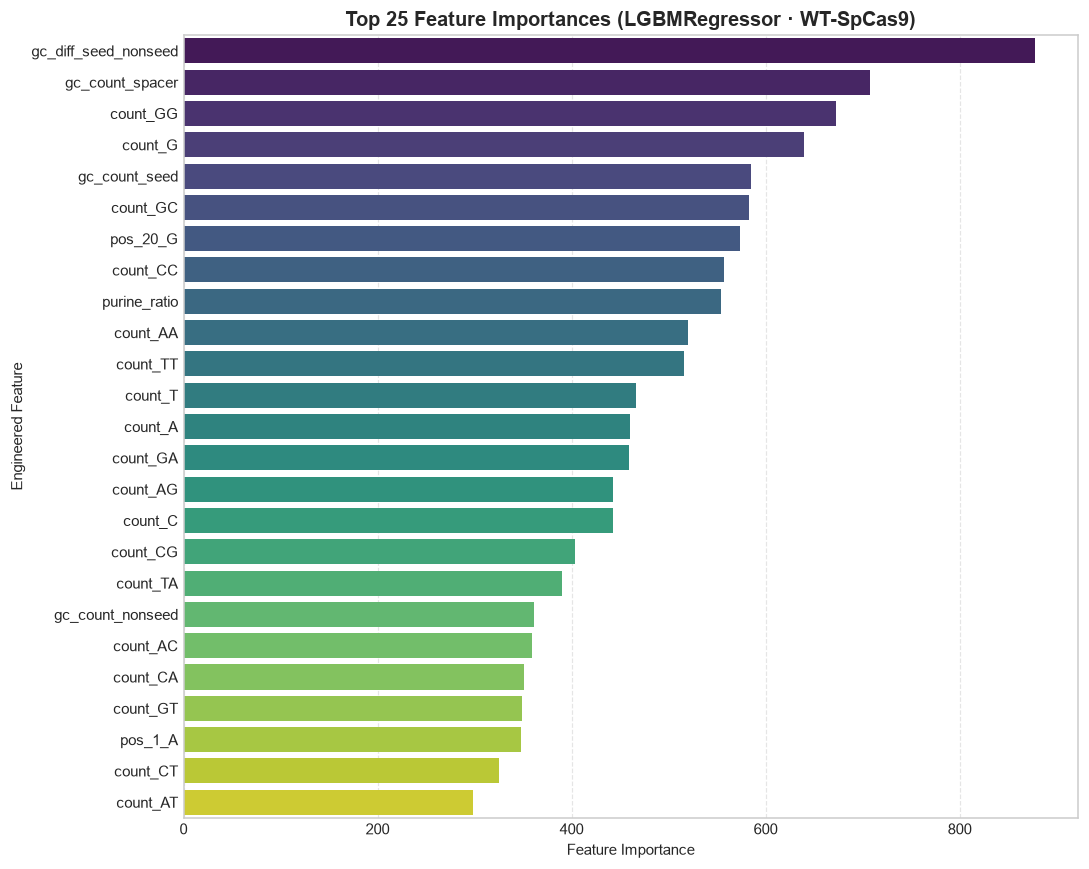

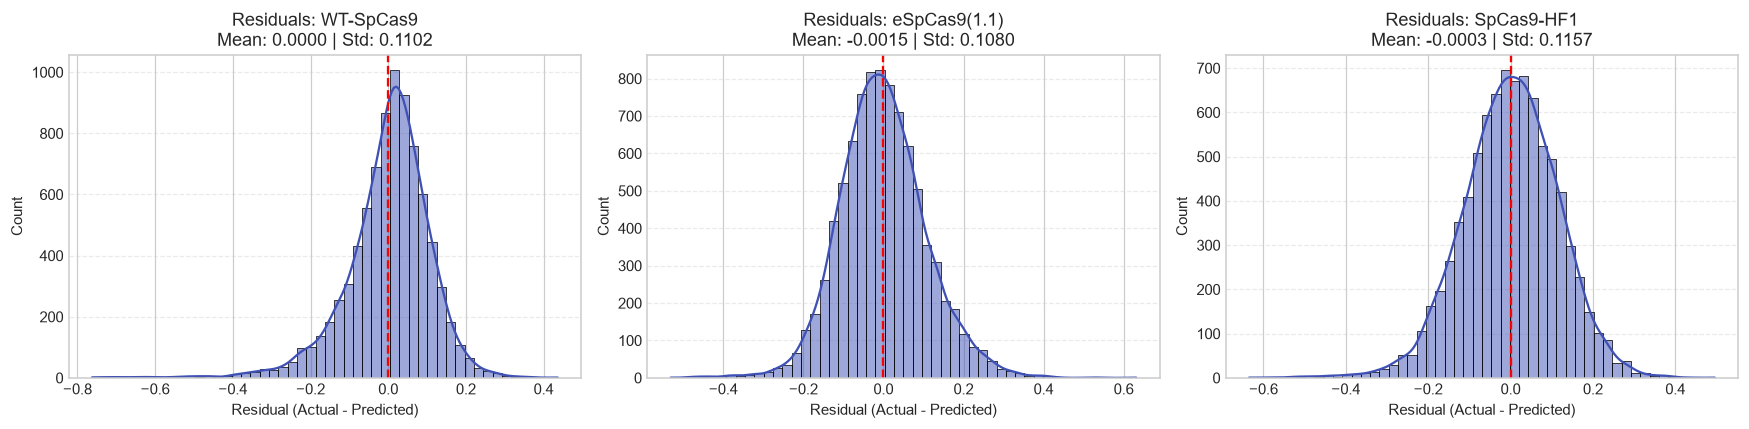

In [8]:
# Pick the "showcase" model: Ensemble if present, else the best booster, else Ridge.
def best_model_name():
    if any("Ensemble" in p for p in all_test_preds.values()):
        return "Ensemble"
    for cand in ["LightGBM", "XGBoost", "CatBoost", "Ridge"]:
        if all(cand in all_test_preds[t] for t in config.TARGET_COLS):
            return cand
    return "Ridge"

show = best_model_name()
print("Showcase model:", show)

# Fig 1: model comparison
fig = plots.plot_model_comparison(metrics_df)
fig.savefig(paths.figures / "fig1_model_comparison.png", dpi=300)
fig.show()

# Fig 2: predicted vs actual
y_true = {t: variant_splits[t]["test"]["y"] for t in config.TARGET_COLS}
y_pred = {t: all_test_preds[t][show] for t in config.TARGET_COLS}
fig = plots.plot_pred_vs_actual(y_true, y_pred, model_label=show)
fig.savefig(paths.figures / "fig2_pred_vs_actual.png", dpi=300)
fig.show()

# Fig 3: feature importance (first available booster; else |Ridge coef|)
import numpy as np
wt_models = all_models["WT_Efficiency"]
imp_model = next((wt_models[b] for b in ["LightGBM", "XGBoost", "CatBoost"]
                  if b in wt_models), None)
if imp_model is not None:
    imp = imp_model.feature_importances_
    title = f"Top 25 Feature Importances ({type(imp_model).__name__} · WT-SpCas9)"
else:
    imp = np.abs(wt_models["Ridge"].coef_)
    title = "Top 25 Features by |Ridge coefficient| · WT-SpCas9"
fig = plots.plot_feature_importance(feature_names, imp, title)
fig.savefig(paths.figures / "fig3_feature_importance.png", dpi=300)
fig.show()

# Fig 4: residuals
resid = {t: variant_splits[t]["test"]["y"] - all_test_preds[t][show]
         for t in config.TARGET_COLS}
fig = plots.plot_residuals(resid)
fig.savefig(paths.figures / "fig4_residuals.png", dpi=300)
fig.show()

## 8. Serialise models & export test predictions
Models are saved to `models/`; per-guide test predictions go to
`results/tier1_test_predictions.csv` so the later tiers can be benchmarked
against this baseline on identical held-out guides.

In [9]:
import joblib
import pandas as pd

n_saved = 0
for target, fitted in all_models.items():
    for name, model in fitted.items():
        fname = f"{name.lower()}_{config.TARGET_KEYS[target]}.joblib"
        joblib.dump(model, paths.models / fname)
        n_saved += 1
print(f"Saved {n_saved} models -> {paths.models}")

pred_frames = []
for target in config.TARGET_COLS:
    s = variant_splits[target]
    frame = {"gRNA_ID": s["test"]["id"], "Target": target,
             "Actual": s["test"]["y"]}
    for name, p in all_test_preds[target].items():
        frame[f"Pred_{name}"] = p
    pred_frames.append(pd.DataFrame(frame))

preds_df = pd.concat(pred_frames, ignore_index=True)
preds_csv = paths.results / "tier1_test_predictions.csv"
preds_df.to_csv(preds_csv, index=False)
print(f"Saved {len(preds_df):,} test predictions -> {preds_csv}")
preds_df.head()

Saved 12 models -> C:\conda_projects\mlsn-group-2\models
Saved 25,668 test predictions -> C:\conda_projects\mlsn-group-2\results\tier1_test_predictions.csv


,gRNA_ID,Target,Actual,Pred_Ridge,Pred_LightGBM,Pred_XGBoost,Pred_CatBoost,Pred_Ensemble
0,GRNA-5,WT_Efficiency,0.045803,0.409139,0.002402,0.017317,0.088835,0.036184
1,GRNA-7,WT_Efficiency,0.133755,0.487140,0.209286,0.198728,0.152205,0.186740
2,GRNA-35,WT_Efficiency,0.146461,0.541946,0.230587,0.273428,0.277241,0.260419
3,GRNA-41,WT_Efficiency,0.168653,0.517603,0.150518,0.136310,0.181727,0.156185
4,GRNA-42,WT_Efficiency,0.066536,0.180040,-0.078551,-0.068163,-0.131735,-0.092816


## ✅ Tier-1 summary & next steps

**Takeaways**
- Tree ensembles (LightGBM / XGBoost / CatBoost) on the 439 engineered features
  reach Pearson *r* ≈ 0.70–0.78 across the three variants — comfortably above the
  linear Ridge floor, confirming non-linear positional interactions matter.
- Feature importances concentrate in the **PAM-proximal seed region** and GC
  content, consistent with R-loop biophysics; the `poly_T_ge4` Pol III terminator
  is a strong negative signal.

**Next tiers**
- **Tier 2 (deep learning):** 1D-CNN and BiLSTM on the one-hot / token encodings
  from `features.encode_sequences` — no manual feature engineering.
- **Tier 3 (bio-features + multi-task):** CNN/BiLSTM augmented with biological
  features, and a shared backbone predicting all three variants jointly
  (`deephf_clean_multitask.csv`).